In [1]:
import pandas as pd
import numpy as np

In [2]:
# Charger les datasets
df_5g = pd.read_csv('dataset1_5g_network_kpi.csv') #Dataset 5G KPI
df_ho = pd.read_csv('network_logs_1.csv') #Dataset Handover
df_processed = pd.read_csv('ds1_processed.csv') #Dataset 5G traitée

In [3]:
# Explorer 5G KPI
print("=" * 50)
print("5G KPI DATASET")
print(f"Lignes: {df_5g.shape[0]} | Colonnes: {df_5g.shape[1]}")
print("\nColonnes:", df_5g.columns.tolist())
print("\nAperçu:")
print(df_5g.head(3))

5G KPI DATASET
Lignes: 5000 | Colonnes: 13

Colonnes: ['timestamp', 'cell_id', 'cell_type', 'slice_type', 'throughput_mbps', 'latency_ms', 'packet_loss_pct', 'handover_count', 'rsrp_dbm', 'rsrq_db', 'prb_utilization_pct', 'active_users', 'sla_compliant']

Aperçu:
             timestamp   cell_id cell_type slice_type  throughput_mbps  \
0  2024-01-01 00:00:00  CELL_007     micro       eMBB           864.50   
1  2024-01-01 00:01:00  CELL_020     micro       mMTC            48.97   
2  2024-01-01 00:02:00  CELL_015     macro       mMTC            53.18   

   latency_ms  packet_loss_pct  handover_count  rsrp_dbm  rsrq_db  \
0       6.418           0.4494               3     -97.3    -7.29   
1      29.693           0.5957               8    -104.8    -6.69   
2      10.869           0.3442               2    -103.8   -14.02   

   prb_utilization_pct  active_users  sla_compliant  
0                 56.2            36              1  
1                 35.5           197              1  


In [4]:
# Explorer Handover
print("\n" + "=" * 50)
print("NETWORK LOGS DATASET")
print(f"Lignes: {df_ho.shape[0]} | Colonnes: {df_ho.shape[1]}")
print("\nColonnes:", df_ho.columns.tolist())
print("\nAperçu:")
print(df_ho.head(3))


NETWORK LOGS DATASET
Lignes: 10570 | Colonnes: 15

Colonnes: ['Timestamp', 'DeviceID', 'deviceMake', 'deviceModel', 'Network provi. ', ' NetworkType', 'RSRP', 'RSRQ', 'SINR', 'PCI', 'Downlink(Mbps)', 'Uplink(Mbps)', 'Velocity(km/h)', 'Latitude', 'Longitude']

Aperçu:
                 Timestamp          DeviceID deviceMake deviceModel  \
0  2025-08-31 22:12:02.008  65bb12ad684ceba4    samsung   SM-S901E    
1  2025-08-31 22:12:00.997  65bb12ad684ceba4    samsung   SM-S901E    
2  2025-08-31 22:11:59.990  65bb12ad684ceba4    samsung   SM-S901E    

  Network provi.   NetworkType     RSRP    RSRQ  SINR    PCI Downlink(Mbps)  \
0          airtel     LTE (4G)  -99 dBm  -12 dB  0 dB  371.0        29 Mbps   
1          airtel     LTE (4G)  -99 dBm  -12 dB  0 dB  371.0        29 Mbps   
2          airtel     LTE (4G)  -99 dBm  -12 dB  0 dB  371.0        29 Mbps   

  Uplink(Mbps) Velocity(km/h)   Latitude  Longitude  
0      18 Mbps     11.05 km/h  18.109974  83.395252  
1      18 Mbps     12

In [5]:
# Explorer Processed
print("\n" + "=" * 50)
print("PROCESSED DATASET")
print(f"Lignes: {df_processed.shape[0]} | Colonnes: {df_processed.shape[1]}")
print("\nColonnes:", df_processed.columns.tolist())
print("\nAperçu:")
print(df_processed.head(3))


PROCESSED DATASET
Lignes: 5000 | Colonnes: 30

Colonnes: ['timestamp', 'cell_id', 'cell_type', 'slice_type', 'throughput_mbps', 'latency_ms', 'packet_loss_pct', 'handover_count', 'rsrp_dbm', 'rsrq_db', 'prb_utilization_pct', 'active_users', 'sla_compliant', 'hour_of_day', 'day_of_week', 'is_peak_hour', 'throughput_per_user', 'spectral_efficiency', 'cell_type_enc', 'slice_type_enc', 'throughput_mbps_norm', 'latency_ms_norm', 'packet_loss_pct_norm', 'handover_count_norm', 'rsrp_dbm_norm', 'rsrq_db_norm', 'prb_utilization_pct_norm', 'active_users_norm', 'throughput_per_user_norm', 'spectral_efficiency_norm']

Aperçu:
             timestamp   cell_id cell_type slice_type  throughput_mbps  \
0  2024-01-01 00:00:00  CELL_007     micro       eMBB           864.50   
1  2024-01-01 00:01:00  CELL_020     micro       mMTC            48.97   
2  2024-01-01 00:02:00  CELL_015     macro       mMTC            53.18   

   latency_ms  packet_loss_pct  handover_count  rsrp_dbm  rsrq_db  ...  \
0     

In [6]:
# ÉTAPE 2 — NETTOYAGE 

# On travaille avec le dataset déjà processé
df = df_processed.copy()

# ---- Vérifier valeurs manquantes ----
print("Valeurs manquantes:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# ---- Supprimer doublons ----
avant = len(df)
df = df.drop_duplicates()
print(f"\n Doublons supprimés: {avant - len(df)}")

Valeurs manquantes:
Series([], dtype: int64)

 Doublons supprimés: 0


In [7]:
# CRÉER COLONNE QoS

def create_qos(row):
    if (row['throughput_mbps'] > 30 and
        row['latency_ms'] < 50 and
        row['packet_loss_pct'] < 2 and
        row['rsrp_dbm'] > -100):
        return 1  # Bonne QoS 
    else:
        return 0  # Mauvaise QoS 

df['QoS'] = df.apply(create_qos, axis=1)

# Résultat 
print("\n Distribution QoS:")
print(df['QoS'].value_counts())
print(f"\n Bonne QoS: {df['QoS'].sum()} lignes ({df['QoS'].mean()*100:.1f}%)")
print(f" Mauvaise QoS: {(df['QoS']==0).sum()} lignes ({(1-df['QoS'].mean())*100:.1f}%)")


 Distribution QoS:
QoS
1    2773
0    2227
Name: count, dtype: int64

 Bonne QoS: 2773 lignes (55.5%)
 Mauvaise QoS: 2227 lignes (44.5%)


In [8]:
# NETTOYAGE du df_ho
df_ho_clean = df_ho.copy()

# Supprimer doublons
df_ho_clean = df_ho_clean.drop_duplicates()

# Renommer colonnes pour simplicité
df_ho_clean.columns = df_ho_clean.columns.str.strip()

# Garder colonnes utiles
cols_utiles = ['RSRP', 'RSRQ', 'SINR', 'Downlink(Mbps)', 'Uplink(Mbps)', 'Velocity(km/h)', 'NetworkType']
df_ho_clean = df_ho_clean[cols_utiles].dropna()

print("\n Network Logs nettoyé:")
print(f"Lignes: {df_ho_clean.shape[0]}")
print(df_ho_clean.head(3))

# Sauvegarder
df.to_csv('df_5g_clean.csv', index=False)
df_ho_clean.to_csv('df_ho_clean.csv', index=False)
print("\n Datasets sauvegardés !")


 Network Logs nettoyé:
Lignes: 10250
      RSRP    RSRQ  SINR Downlink(Mbps) Uplink(Mbps) Velocity(km/h)  \
0  -99 dBm  -12 dB  0 dB        29 Mbps      18 Mbps     11.05 km/h   
1  -99 dBm  -12 dB  0 dB        29 Mbps      18 Mbps     12.64 km/h   
2  -99 dBm  -12 dB  0 dB        29 Mbps      18 Mbps     13.00 km/h   

  NetworkType  
0    LTE (4G)  
1    LTE (4G)  
2    LTE (4G)  

 Datasets sauvegardés !


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec

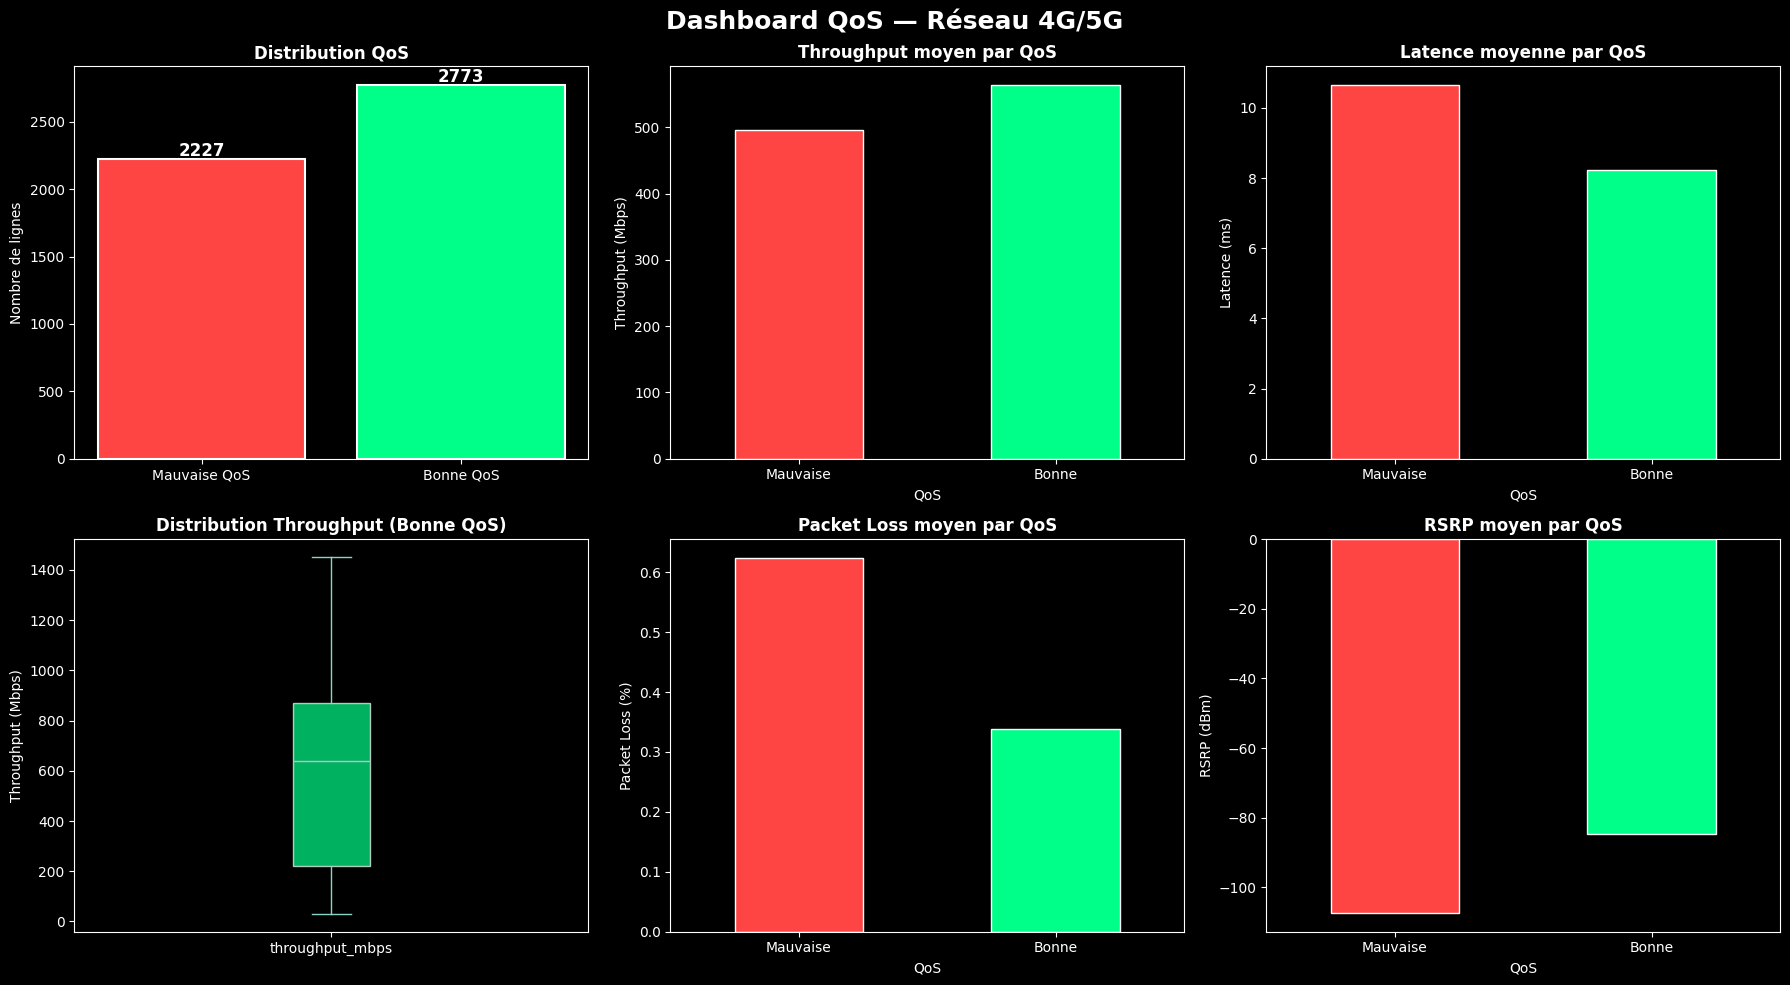

Dashboard sauvegardé : dashboard_qos.png


In [25]:
# Style
plt.style.use('dark_background')
colors = ['#FF4444', '#00FF88']  # Rouge=Mauvaise, Vert=Bonne

# FIGURE 1 — VUE GLOBALE QoS
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Dashboard QoS — Réseau 4G/5G', fontsize=18, fontweight='bold', color='white')

# --- Graphique 1 : Distribution QoS ---
ax1 = axes[0, 0]
qos_counts = df['QoS'].value_counts()
bars = ax1.bar(['Mauvaise QoS', 'Bonne QoS'], 
               [qos_counts[0], qos_counts[1]], 
               color=colors, edgecolor='white', linewidth=1.5)
ax1.set_title('Distribution QoS', fontweight='bold')
ax1.set_ylabel('Nombre de lignes')
for bar, val in zip(bars, [qos_counts[0], qos_counts[1]]):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
             str(val), ha='center', fontweight='bold', fontsize=12)

# --- Graphique 2 : Throughput vs QoS ---
ax2 = axes[0, 1]
df.groupby('QoS')['throughput_mbps'].mean().plot(kind='bar', ax=ax2, color=colors, edgecolor='white')
ax2.set_title('Throughput moyen par QoS', fontweight='bold')
ax2.set_ylabel('Throughput (Mbps)')
ax2.set_xticklabels(['Mauvaise', 'Bonne'], rotation=0)

# --- Graphique 3 : Latence vs QoS ---
ax3 = axes[0, 2]
df.groupby('QoS')['latency_ms'].mean().plot(kind='bar', ax=ax3, color=colors, edgecolor='white')
ax3.set_title('Latence moyenne par QoS', fontweight='bold')
ax3.set_ylabel('Latence (ms)')
ax3.set_xticklabels(['Mauvaise', 'Bonne'], rotation=0)

# --- Graphique 4 : Boxplot Throughput ---
ax4 = axes[1, 0]
df[df['QoS']==1]['throughput_mbps'].plot(kind='box', ax=ax4, patch_artist=True,
    boxprops=dict(facecolor='#00FF88', alpha=0.7))
ax4.set_title('Distribution Throughput (Bonne QoS)', fontweight='bold')
ax4.set_ylabel('Throughput (Mbps)')

# --- Graphique 5 : Packet Loss vs QoS ---
ax5 = axes[1, 1]
df.groupby('QoS')['packet_loss_pct'].mean().plot(kind='bar', ax=ax5, 
    color=colors, edgecolor='white')
ax5.set_title('Packet Loss moyen par QoS', fontweight='bold')
ax5.set_ylabel('Packet Loss (%)')
ax5.set_xticklabels(['Mauvaise', 'Bonne'], rotation=0)

# --- Graphique 6 : RSRP vs QoS ---
ax6 = axes[1, 2]
df.groupby('QoS')['rsrp_dbm'].mean().plot(kind='bar', ax=ax6, 
    color=colors, edgecolor='white')
ax6.set_title('RSRP moyen par QoS', fontweight='bold')
ax6.set_ylabel('RSRP (dBm)')
ax6.set_xticklabels(['Mauvaise', 'Bonne'], rotation=0)

plt.tight_layout()
plt.savefig('dashboard_qos.png', dpi=150, bbox_inches='tight')
plt.show()
print("Dashboard sauvegardé : dashboard_qos.png")

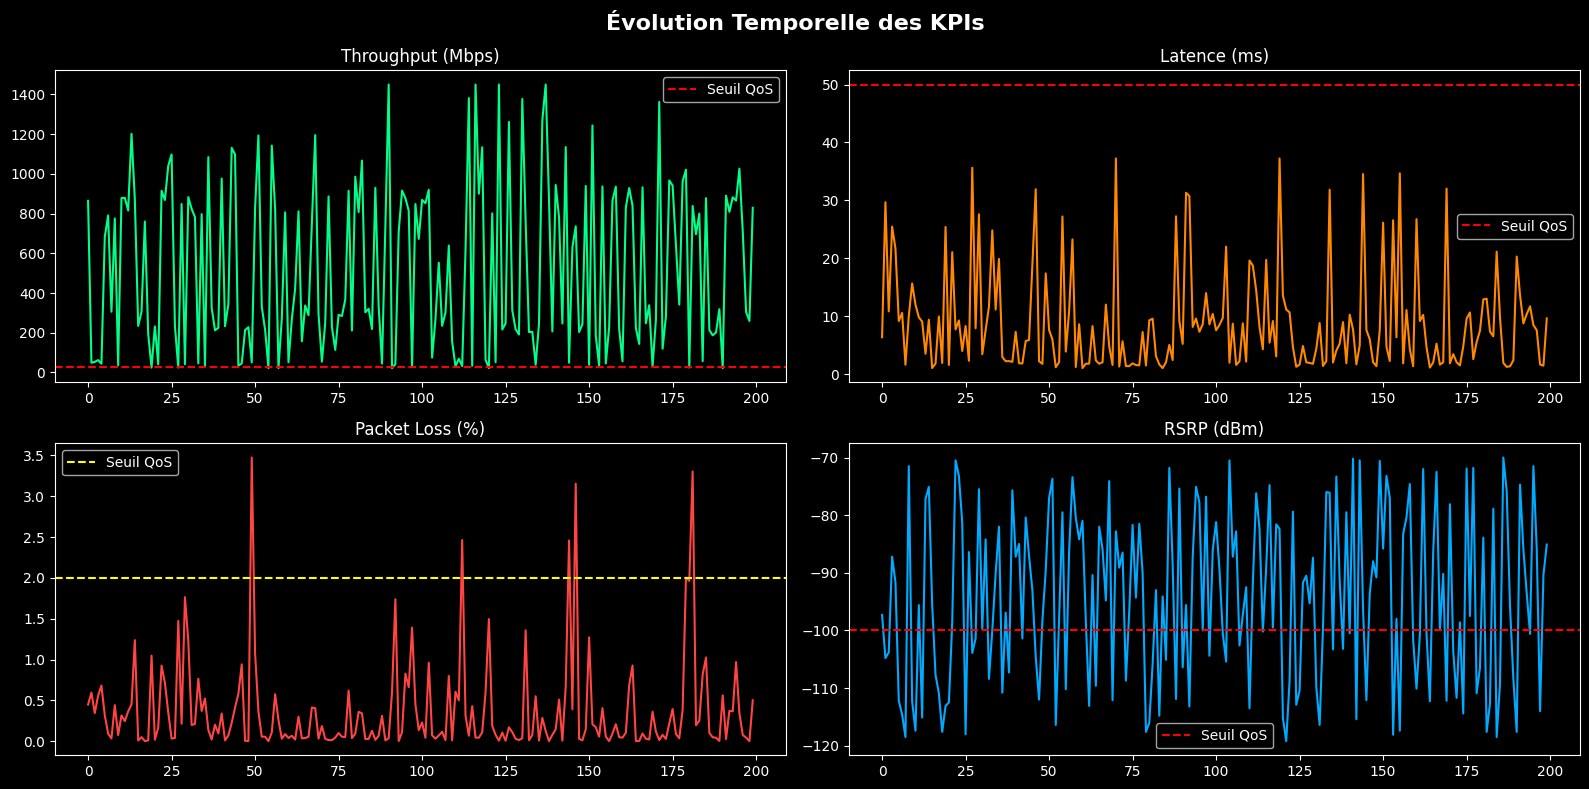

Évolution temporelle sauvegardée !


In [11]:
# FIGURE 2 — ÉVOLUTION TEMPORELLE

fig2, axes2 = plt.subplots(2, 2, figsize=(16, 8))
fig2.suptitle('Évolution Temporelle des KPIs', fontsize=16, fontweight='bold')

# Prendre 200 points pour visualisation
sample = df.head(200)

axes2[0,0].plot(sample['throughput_mbps'].values, color='#00FF88', linewidth=1.5)
axes2[0,0].set_title('Throughput (Mbps)')
axes2[0,0].axhline(y=30, color='red', linestyle='--', label='Seuil QoS')
axes2[0,0].legend()

axes2[0,1].plot(sample['latency_ms'].values, color='#FF8800', linewidth=1.5)
axes2[0,1].set_title('Latence (ms)')
axes2[0,1].axhline(y=50, color='red', linestyle='--', label='Seuil QoS')
axes2[0,1].legend()

axes2[1,0].plot(sample['packet_loss_pct'].values, color='#FF4444', linewidth=1.5)
axes2[1,0].set_title('Packet Loss (%)')
axes2[1,0].axhline(y=2, color='yellow', linestyle='--', label='Seuil QoS')
axes2[1,0].legend()

axes2[1,1].plot(sample['rsrp_dbm'].values, color='#00AAFF', linewidth=1.5)
axes2[1,1].set_title('RSRP (dBm)')
axes2[1,1].axhline(y=-100, color='red', linestyle='--', label='Seuil QoS')
axes2[1,1].legend()

plt.tight_layout()
plt.savefig('evolution_kpis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Évolution temporelle sauvegardée !")

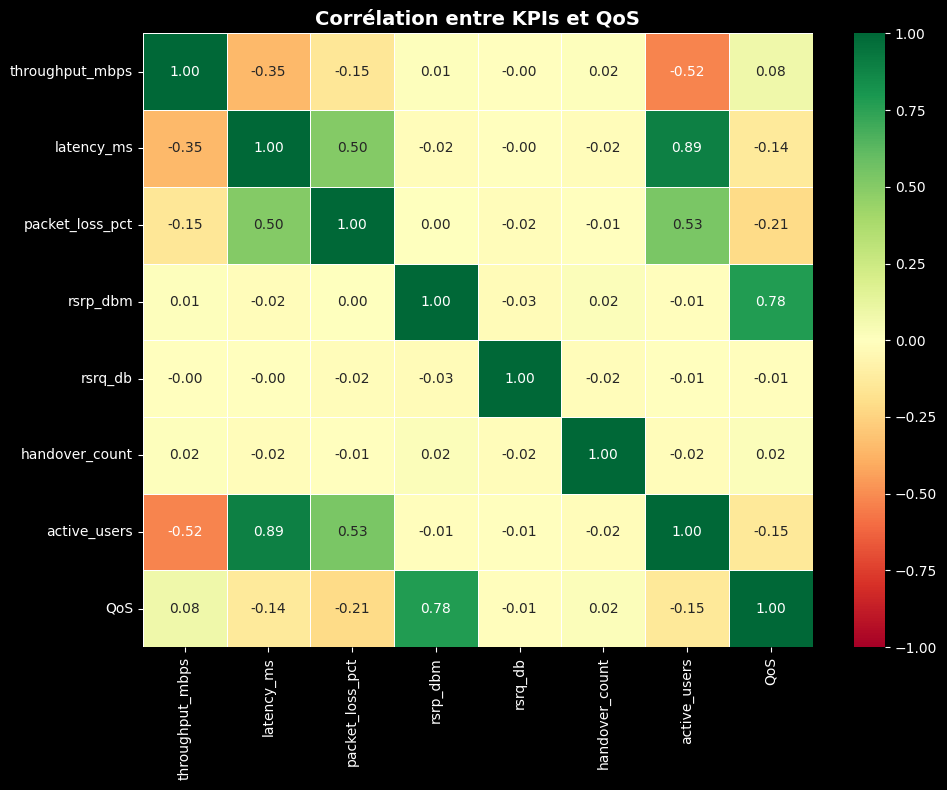

Heatmap sauvegardée !


In [12]:
# FIGURE 3 — HEATMAP CORRÉLATIONS

fig3, ax = plt.subplots(figsize=(10, 8))
cols_corr = ['throughput_mbps', 'latency_ms', 'packet_loss_pct', 
             'rsrp_dbm', 'rsrq_db', 'handover_count', 'active_users', 'QoS']
corr = df[cols_corr].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn', 
            ax=ax, linewidths=0.5, vmin=-1, vmax=1)
ax.set_title('Corrélation entre KPIs et QoS', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Heatmap sauvegardée !")

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, roc_curve, auc)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [14]:
# PRÉPARATION DONNÉES ML

features = ['throughput_mbps', 'latency_ms', 'packet_loss_pct', 'rsrp_dbm', 'rsrq_db', 'handover_count', 'active_users']

X = df[features]
y = df['QoS']

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Normalisation
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f"Train: {X_train.shape[0]} lignes")
print(f"Test:  {X_test.shape[0]} lignes")

Train: 4000 lignes
Test:  1000 lignes


In [15]:
# MODÈLE 1 — LOGISTIC REGRESSION

lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_sc, y_train)
y_pred_lr = lr.predict(X_test_sc)
acc_lr = accuracy_score(y_test, y_pred_lr)
print(f"\n Logistic Regression Accuracy: {acc_lr*100:.2f}%")
print(classification_report(y_test, y_pred_lr, target_names=['Mauvaise QoS', 'Bonne QoS']))


 Logistic Regression Accuracy: 93.90%
              precision    recall  f1-score   support

Mauvaise QoS       0.92      0.95      0.93       445
   Bonne QoS       0.96      0.93      0.94       555

    accuracy                           0.94      1000
   macro avg       0.94      0.94      0.94      1000
weighted avg       0.94      0.94      0.94      1000



In [16]:
# MODÈLE 2 — RANDOM FOREST

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_sc, y_train)
y_pred_rf = rf.predict(X_test_sc)
acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {acc_rf*100:.2f}%")
print(classification_report(y_test, y_pred_rf, target_names=['Mauvaise QoS', 'Bonne QoS']))

Random Forest Accuracy: 100.00%
              precision    recall  f1-score   support

Mauvaise QoS       1.00      1.00      1.00       445
   Bonne QoS       1.00      1.00      1.00       555

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



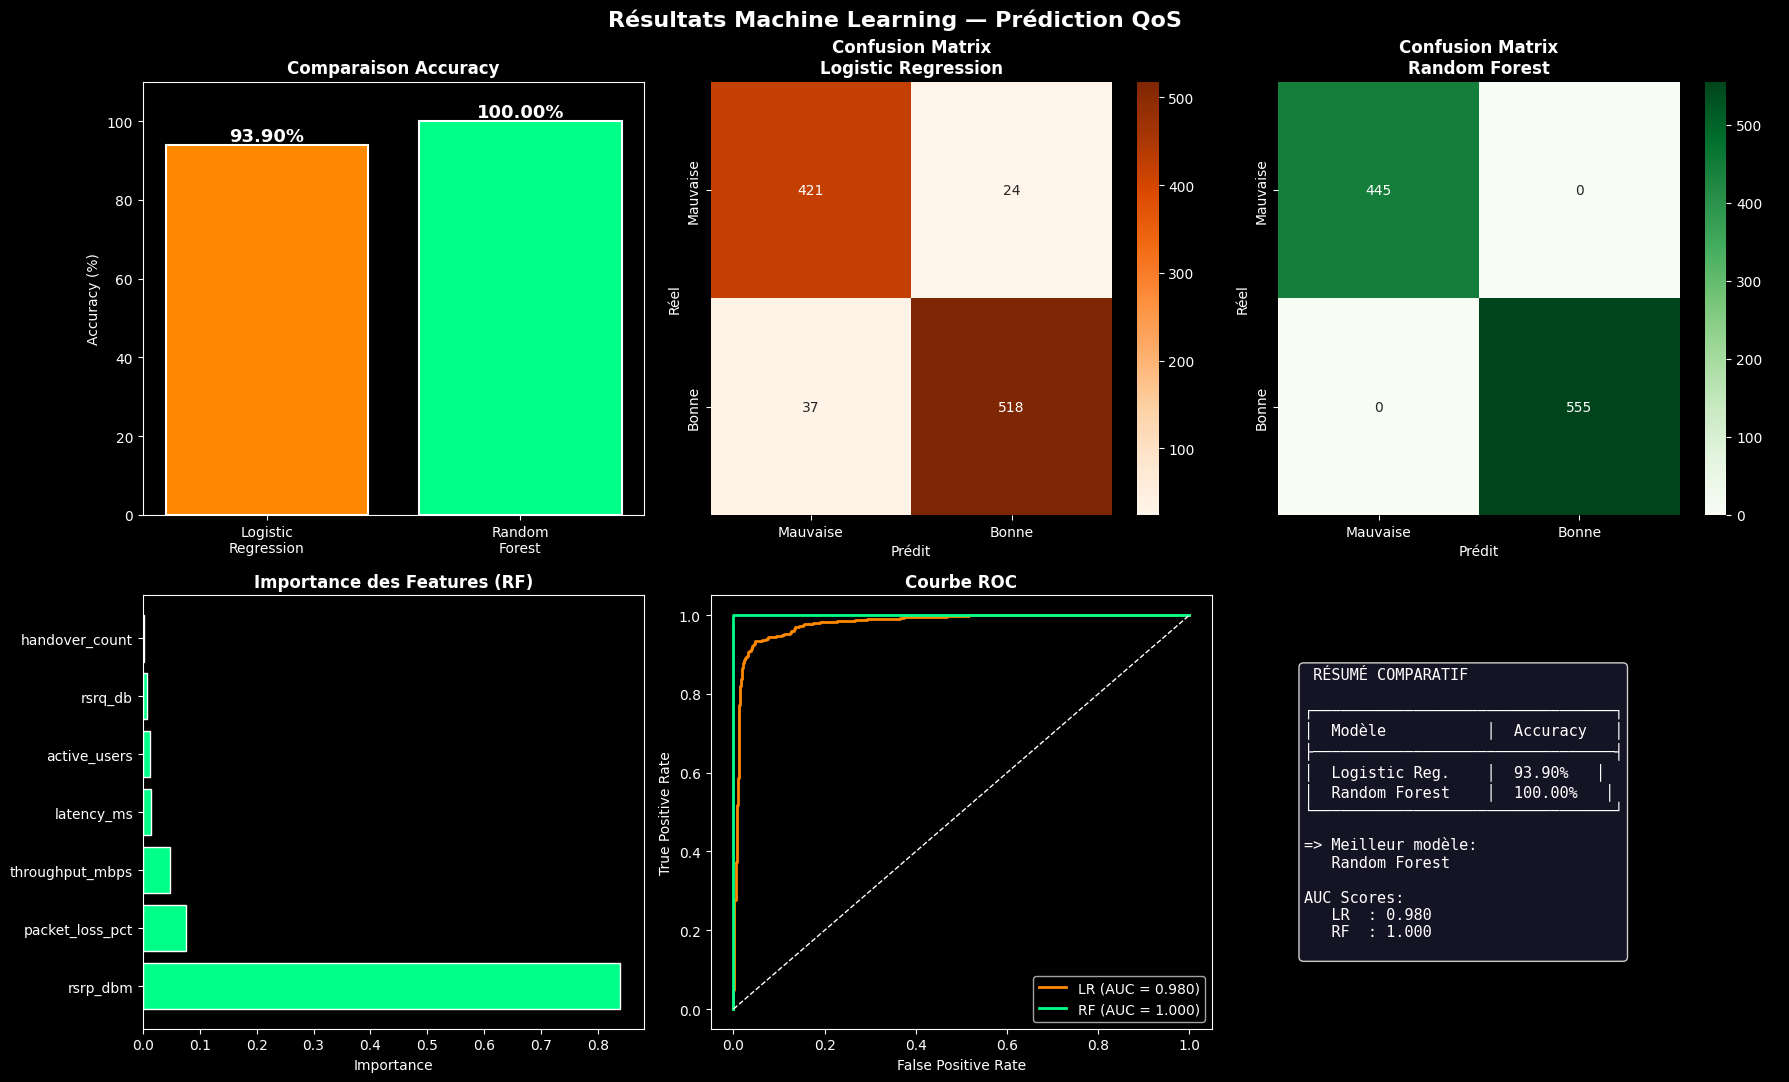

Résultats ML sauvegardés !


In [17]:
# VISUALISATIONS ML

plt.style.use('dark_background')
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Résultats Machine Learning — Prédiction QoS', 
             fontsize=16, fontweight='bold')

# --- 1. Comparaison Accuracy ---
ax1 = axes[0, 0]
models = ['Logistic\nRegression', 'Random\nForest']
accs = [acc_lr*100, acc_rf*100]
bars = ax1.bar(models, accs, color=['#FF8800', '#00FF88'], 
               edgecolor='white', linewidth=1.5)
ax1.set_ylim(0, 110)
ax1.set_title('Comparaison Accuracy', fontweight='bold')
ax1.set_ylabel('Accuracy (%)')
for bar, val in zip(bars, accs):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{val:.2f}%', ha='center', fontweight='bold', fontsize=13)

# --- 2. Confusion Matrix LR ---
ax2 = axes[0, 1]
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Oranges', ax=ax2,
            xticklabels=['Mauvaise', 'Bonne'],
            yticklabels=['Mauvaise', 'Bonne'])
ax2.set_title('Confusion Matrix\nLogistic Regression', fontweight='bold')
ax2.set_ylabel('Réel')
ax2.set_xlabel('Prédit')

# --- 3. Confusion Matrix RF ---
ax3 = axes[0, 2]
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=ax3,
            xticklabels=['Mauvaise', 'Bonne'],
            yticklabels=['Mauvaise', 'Bonne'])
ax3.set_title('Confusion Matrix\nRandom Forest', fontweight='bold')
ax3.set_ylabel('Réel')
ax3.set_xlabel('Prédit')

# --- 4. Feature Importance RF ---
ax4 = axes[1, 0]
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
ax4.barh([features[i] for i in indices], 
          importances[indices], color='#00FF88', edgecolor='white')
ax4.set_title('Importance des Features (RF)', fontweight='bold')
ax4.set_xlabel('Importance')

# --- 5. Courbe ROC ---
ax5 = axes[1, 1]
# LR
y_prob_lr = lr.predict_proba(X_test_sc)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = auc(fpr_lr, tpr_lr)
ax5.plot(fpr_lr, tpr_lr, color='#FF8800', lw=2, 
         label=f'LR (AUC = {auc_lr:.3f})')
# RF
y_prob_rf = rf.predict_proba(X_test_sc)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = auc(fpr_rf, tpr_rf)
ax5.plot(fpr_rf, tpr_rf, color='#00FF88', lw=2,
         label=f'RF (AUC = {auc_rf:.3f})')
ax5.plot([0,1], [0,1], 'w--', lw=1)
ax5.set_title('Courbe ROC', fontweight='bold')
ax5.set_xlabel('False Positive Rate')
ax5.set_ylabel('True Positive Rate')
ax5.legend()

# --- 6. Résumé comparatif ---
ax6 = axes[1, 2]
ax6.axis('off')
summary = f""" RÉSUMÉ COMPARATIF

┌─────────────────────────────────┐
│  Modèle           │  Accuracy   │
├─────────────────────────────────┤
│  Logistic Reg.    │  {acc_lr*100:.2f}%   │
│  Random Forest    │  {acc_rf*100:.2f}%   │
└─────────────────────────────────┘

=> Meilleur modèle:
   {'Random Forest' if acc_rf >= acc_lr else 'Logistic Regression'}

AUC Scores:
   LR  : {auc_lr:.3f}
   RF  : {auc_rf:.3f}
"""
ax6.text(0.05, 0.5, summary, transform=ax6.transAxes,
         fontsize=11, verticalalignment='center',
         fontfamily='monospace', color='white',
         bbox=dict(boxstyle='round', facecolor='#1a1a2e', alpha=0.8))

plt.tight_layout()
plt.savefig('resultats_ml.png', dpi=150, bbox_inches='tight')
plt.show()
print("Résultats ML sauvegardés !")

In [18]:
# ÉTAPE 4 — SYSTÈME D'ALERTES


print("SYSTÈME DE SURVEILLANCE RÉSEAU EN TEMPS RÉEL")
print("=" * 55)

def analyser_cellule(cell_data, modele, scaler, features):
    """Analyse une cellule et génère des alertes"""
    alertes = []
    
    # Vérifications KPI
    if cell_data['throughput_mbps'] < 30:
        alertes.append(f" Throughput faible: {cell_data['throughput_mbps']:.1f} Mbps (seuil: 30)")
    if cell_data['latency_ms'] > 50:
        alertes.append(f" Latence élevée: {cell_data['latency_ms']:.1f} ms (seuil: 50)")
    if cell_data['packet_loss_pct'] > 2:
        alertes.append(f" Packet Loss élevé: {cell_data['packet_loss_pct']:.2f}% (seuil: 2%)")
    if cell_data['rsrp_dbm'] < -100:
        alertes.append(f" Signal faible: {cell_data['rsrp_dbm']:.1f} dBm (seuil: -100)")
    
    # Prédiction ML
    X = pd.DataFrame([[cell_data[f] for f in features]], columns=features)
    X_sc = scaler.transform(X)
    prediction = modele.predict(X_sc)[0]
    proba = modele.predict_proba(X_sc)[0]
    
    return prediction, proba, alertes

# Tester sur 5 cellules exemples
print("\n Analyse de 5 cellules réseau:\n")

features_ml = ['throughput_mbps', 'latency_ms', 'packet_loss_pct', 
                'rsrp_dbm', 'rsrq_db', 'handover_count', 'active_users']

for i in range(5):
    cell = df[features_ml + ['QoS']].iloc[i]
    pred, proba, alertes = analyser_cellule(cell, rf, scaler, features_ml)
    
    status = "BONNE QoS" if pred == 1 else "MAUVAISE QoS"
    print(f"━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━")
    print(f" Cellule {i+1} → {status}")
    print(f"   Confiance: {max(proba)*100:.1f}%")
    print(f"   Throughput: {cell['throughput_mbps']:.1f} Mbps | Latence: {cell['latency_ms']:.1f} ms")
    if alertes:
        for a in alertes:
            print(f"   {a}")
    else:
        print(f" Tous les KPIs dans les normes")

print(f"\n━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━")

SYSTÈME DE SURVEILLANCE RÉSEAU EN TEMPS RÉEL

 Analyse de 5 cellules réseau:

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Cellule 1 → BONNE QoS
   Confiance: 100.0%
   Throughput: 864.5 Mbps | Latence: 6.4 ms
 Tous les KPIs dans les normes
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Cellule 2 → MAUVAISE QoS
   Confiance: 98.0%
   Throughput: 49.0 Mbps | Latence: 29.7 ms
    Signal faible: -104.8 dBm (seuil: -100)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Cellule 3 → MAUVAISE QoS
   Confiance: 94.0%
   Throughput: 53.2 Mbps | Latence: 10.9 ms
    Signal faible: -103.8 dBm (seuil: -100)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Cellule 4 → BONNE QoS
   Confiance: 99.0%
   Throughput: 62.4 Mbps | Latence: 25.5 ms
 Tous les KPIs dans les normes
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Cellule 5 → BONNE QoS
   Confiance: 99.0%
   Throughput: 43.9 Mbps | Latence: 21.7 ms
 Tous les KPIs dans les normes

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


In [19]:
# SCÉNARIO RÉEL (pour PPT)

print("\n\n SCÉNARIO : Congestion réseau détectée")
print("=" * 55)

# Simuler une cellule en congestion
cellule_congestion = {
    'throughput_mbps': 8.5,    # très faible
    'latency_ms': 120.0,       # très élevée
    'packet_loss_pct': 5.2,    # élevé
    'rsrp_dbm': -108.0,        # signal faible
    'rsrq_db': -15.0,
    'handover_count': 12,
    'active_users': 280
}

pred, proba, alertes = analyser_cellule(cellule_congestion, rf, scaler, features_ml)

print(f"\n Cellule CELL_007 — Zone urbaine (1800 MHz)")
print(f" Utilisateurs actifs: {cellule_congestion['active_users']}")
print(f"\n KPIs actuels:")
for k, v in cellule_congestion.items():
    print(f"   {k}: {v}")

print(f"\n Prédiction ML: {'DÉGRADATION QoS DÉTECTÉE' if pred==0 else 'QoS Normale'}")
print(f"   Confiance: {max(proba)*100:.1f}%")
print(f"\n Alertes générées:")
for a in alertes:
    print(f"   {a}")
print(f"\n Recommandation: Handover vers cellule voisine recommandé")
print(f"   → Le système anticipe la dégradation AVANT l'impact utilisateur")



 SCÉNARIO : Congestion réseau détectée

 Cellule CELL_007 — Zone urbaine (1800 MHz)
 Utilisateurs actifs: 280

 KPIs actuels:
   throughput_mbps: 8.5
   latency_ms: 120.0
   packet_loss_pct: 5.2
   rsrp_dbm: -108.0
   rsrq_db: -15.0
   handover_count: 12
   active_users: 280

 Prédiction ML: DÉGRADATION QoS DÉTECTÉE
   Confiance: 99.0%

 Alertes générées:
    Throughput faible: 8.5 Mbps (seuil: 30)
    Latence élevée: 120.0 ms (seuil: 50)
    Packet Loss élevé: 5.20% (seuil: 2%)
    Signal faible: -108.0 dBm (seuil: -100)

 Recommandation: Handover vers cellule voisine recommandé
   → Le système anticipe la dégradation AVANT l'impact utilisateur


In [20]:
# ANALYSE NETWORK LOGS (4G/5G)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

plt.style.use('dark_background')

# Nettoyer les colonnes numériques
def extract_number(val):
    if isinstance(val, str):
        return float(val.split()[0])
    return float(val)

df_ho_clean['RSRP_val'] = df_ho_clean['RSRP'].apply(extract_number)
df_ho_clean['RSRQ_val'] = df_ho_clean['RSRQ'].apply(extract_number)
df_ho_clean['SINR_val'] = df_ho_clean['SINR'].apply(extract_number)
df_ho_clean['Downlink_val'] = df_ho_clean['Downlink(Mbps)'].apply(extract_number)
df_ho_clean['Uplink_val'] = df_ho_clean['Uplink(Mbps)'].apply(extract_number)
df_ho_clean['Velocity_val'] = df_ho_clean['Velocity(km/h)'].apply(extract_number)

# Créer QoS pour network logs
df_ho_clean['QoS'] = ((df_ho_clean['RSRP_val'] > -100) & 
                       (df_ho_clean['SINR_val'] > 0) & 
                       (df_ho_clean['Downlink_val'] > 20)).astype(int)

print("Distribution QoS Network Logs:")
print(df_ho_clean['QoS'].value_counts())


Distribution QoS Network Logs:
QoS
0    8633
1    1617
Name: count, dtype: int64


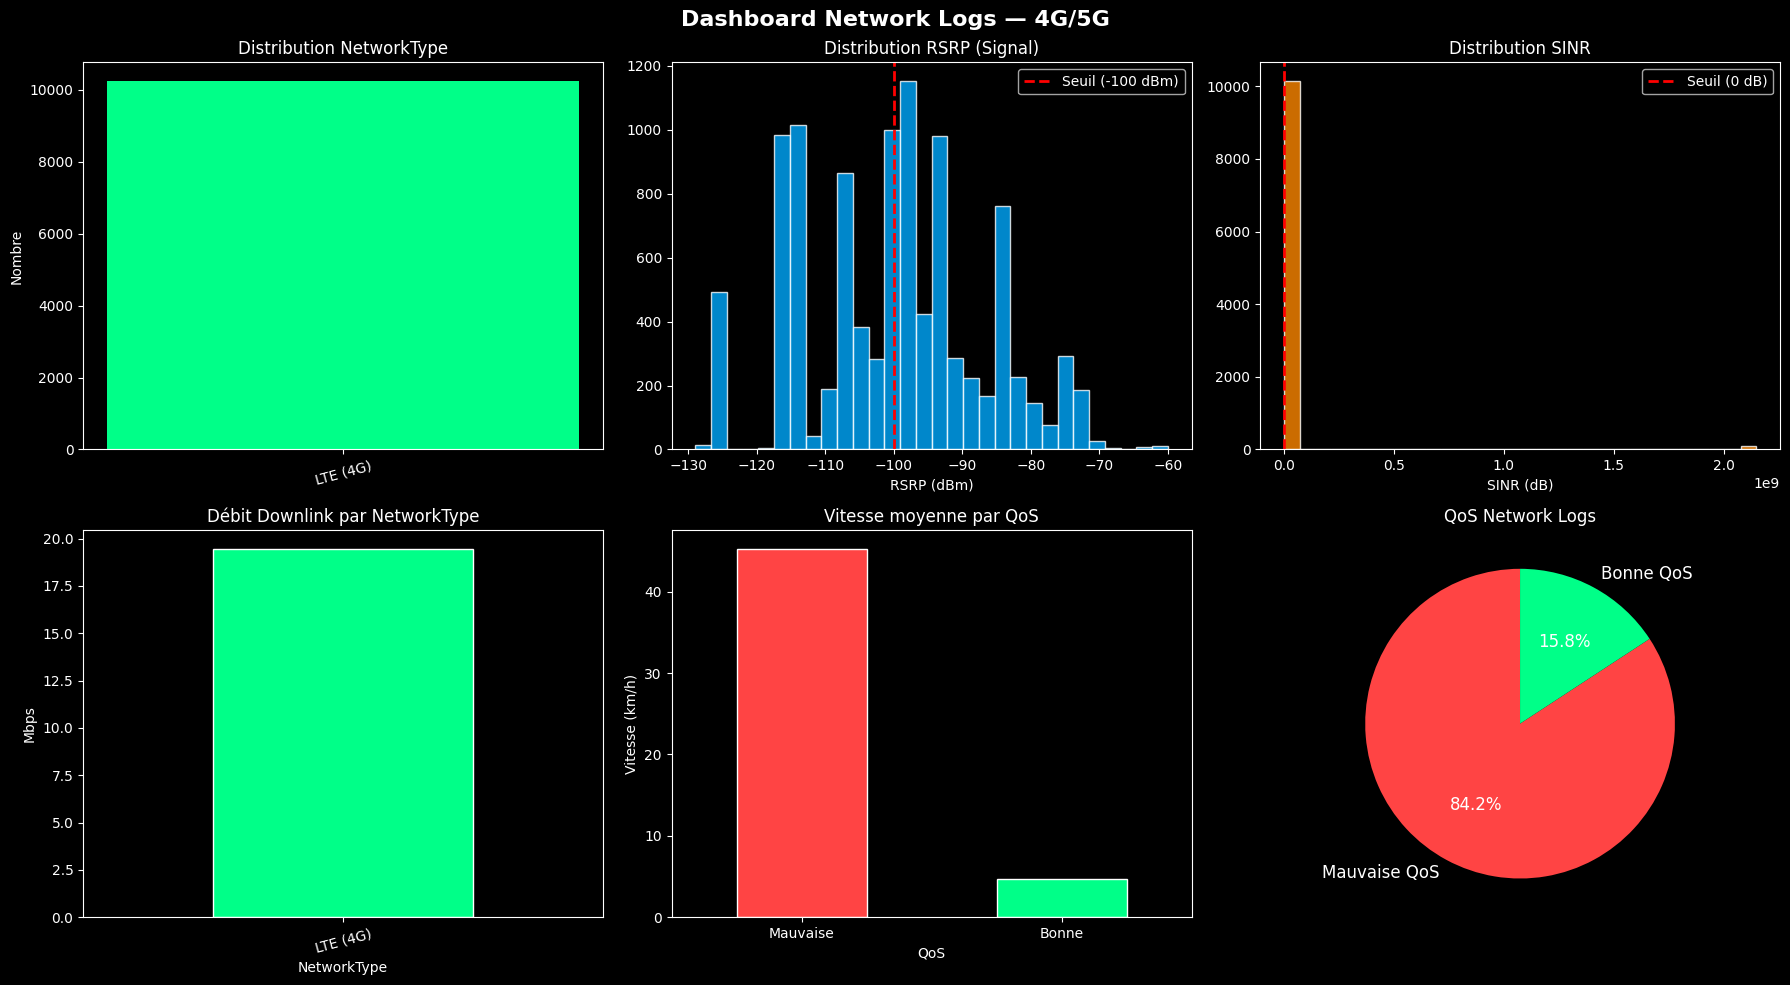

Dashboard Network Logs sauvegardé !


In [21]:
# FIGURE — DASHBOARD NETWORK LOGS

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Dashboard Network Logs — 4G/5G', fontsize=16, fontweight='bold')

# 1. Distribution NetworkType
ax1 = axes[0, 0]
nt_counts = df_ho_clean['NetworkType'].value_counts()
ax1.bar(nt_counts.index, nt_counts.values, color=['#00FF88', '#FF8800', '#00AAFF'])
ax1.set_title('Distribution NetworkType')
ax1.set_ylabel('Nombre')
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=15)

# 2. RSRP Distribution
ax2 = axes[0, 1]
ax2.hist(df_ho_clean['RSRP_val'], bins=30, color='#00AAFF', edgecolor='white', alpha=0.8)
ax2.axvline(x=-100, color='red', linestyle='--', linewidth=2, label='Seuil (-100 dBm)')
ax2.set_title('Distribution RSRP (Signal)')
ax2.set_xlabel('RSRP (dBm)')
ax2.legend()

# 3. SINR Distribution
ax3 = axes[0, 2]
ax3.hist(df_ho_clean['SINR_val'], bins=30, color='#FF8800', edgecolor='white', alpha=0.8)
ax3.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Seuil (0 dB)')
ax3.set_title('Distribution SINR')
ax3.set_xlabel('SINR (dB)')
ax3.legend()

# 4. Downlink vs NetworkType
ax4 = axes[1, 0]
df_ho_clean.groupby('NetworkType')['Downlink_val'].mean().plot(
    kind='bar', ax=ax4, color=['#00FF88', '#FF8800', '#00AAFF'], edgecolor='white')
ax4.set_title('Débit Downlink par NetworkType')
ax4.set_ylabel('Mbps')
ax4.tick_params(axis='x', rotation=15)

# 5. Velocity vs QoS
ax5 = axes[1, 1]
df_ho_clean.groupby('QoS')['Velocity_val'].mean().plot(
    kind='bar', ax=ax5, color=['#FF4444', '#00FF88'], edgecolor='white')
ax5.set_title('Vitesse moyenne par QoS')
ax5.set_ylabel('Vitesse (km/h)')
ax5.set_xticklabels(['Mauvaise', 'Bonne'], rotation=0)

# 6. QoS Distribution Network Logs
ax6 = axes[1, 2]
qos_ho = df_ho_clean['QoS'].value_counts()
ax6.pie([qos_ho.get(0, 0), qos_ho.get(1, 0)], 
        labels=['Mauvaise QoS', 'Bonne QoS'],
        colors=['#FF4444', '#00FF88'],
        autopct='%1.1f%%', startangle=90,
        textprops={'fontsize': 12})
ax6.set_title('QoS Network Logs')

plt.tight_layout()
plt.savefig('dashboard_networklogs.png', dpi=150, bbox_inches='tight')
plt.show()
print("Dashboard Network Logs sauvegardé !")

In [22]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

plt.style.use('dark_background')

# 1. CROSS-VALIDATION (5 folds)

print("=" * 55)
print("CROSS-VALIDATION — 5 Folds")
print("=" * 55)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Logistic Regression
cv_lr = cross_val_score(lr, X_train_sc, y_train, cv=cv, scoring='accuracy')
print(f"\n Logistic Regression:")
print(f"   Scores par fold : {[f'{s*100:.1f}%' for s in cv_lr]}")
print(f"   Moyenne  : {cv_lr.mean()*100:.2f}%")
print(f"   Écart-type: ±{cv_lr.std()*100:.2f}%")

# Random Forest
cv_rf = cross_val_score(rf, X_train_sc, y_train, cv=cv, scoring='accuracy')
print(f"\n Random Forest:")
print(f"   Scores par fold : {[f'{s*100:.1f}%' for s in cv_rf]}")
print(f"   Moyenne  : {cv_rf.mean()*100:.2f}%")
print(f"   Écart-type: ±{cv_rf.std()*100:.2f}%")

CROSS-VALIDATION — 5 Folds

 Logistic Regression:
   Scores par fold : ['94.1%', '91.9%', '92.8%', '91.6%', '95.1%']
   Moyenne  : 93.10%
   Écart-type: ±1.34%

 Random Forest:
   Scores par fold : ['100.0%', '100.0%', '99.9%', '100.0%', '100.0%']
   Moyenne  : 99.98%
   Écart-type: ±0.05%


In [23]:
# 2. FEATURE IMPORTANCE

print("\n" + "=" * 55)
print("IMPORTANCE DES FEATURES (Random Forest)")
print("=" * 55)

feat_imp = pd.Series(rf.feature_importances_, index=features_ml)
feat_imp_sorted = feat_imp.sort_values(ascending=True)

print("\nClassement des KPIs par importance :")
for i, (feat, val) in enumerate(feat_imp_sorted.items()):
    bar = "█" * int(val * 100)
    print(f"  {i+1}. {feat:<25} {val*100:.1f}%  {bar}")


IMPORTANCE DES FEATURES (Random Forest)

Classement des KPIs par importance :
  1. handover_count            0.3%  
  2. rsrq_db                   0.7%  
  3. active_users              1.3%  █
  4. latency_ms                1.5%  █
  5. throughput_mbps           4.8%  ████
  6. packet_loss_pct           7.5%  ███████
  7. rsrp_dbm                  84.0%  ███████████████████████████████████████████████████████████████████████████████████


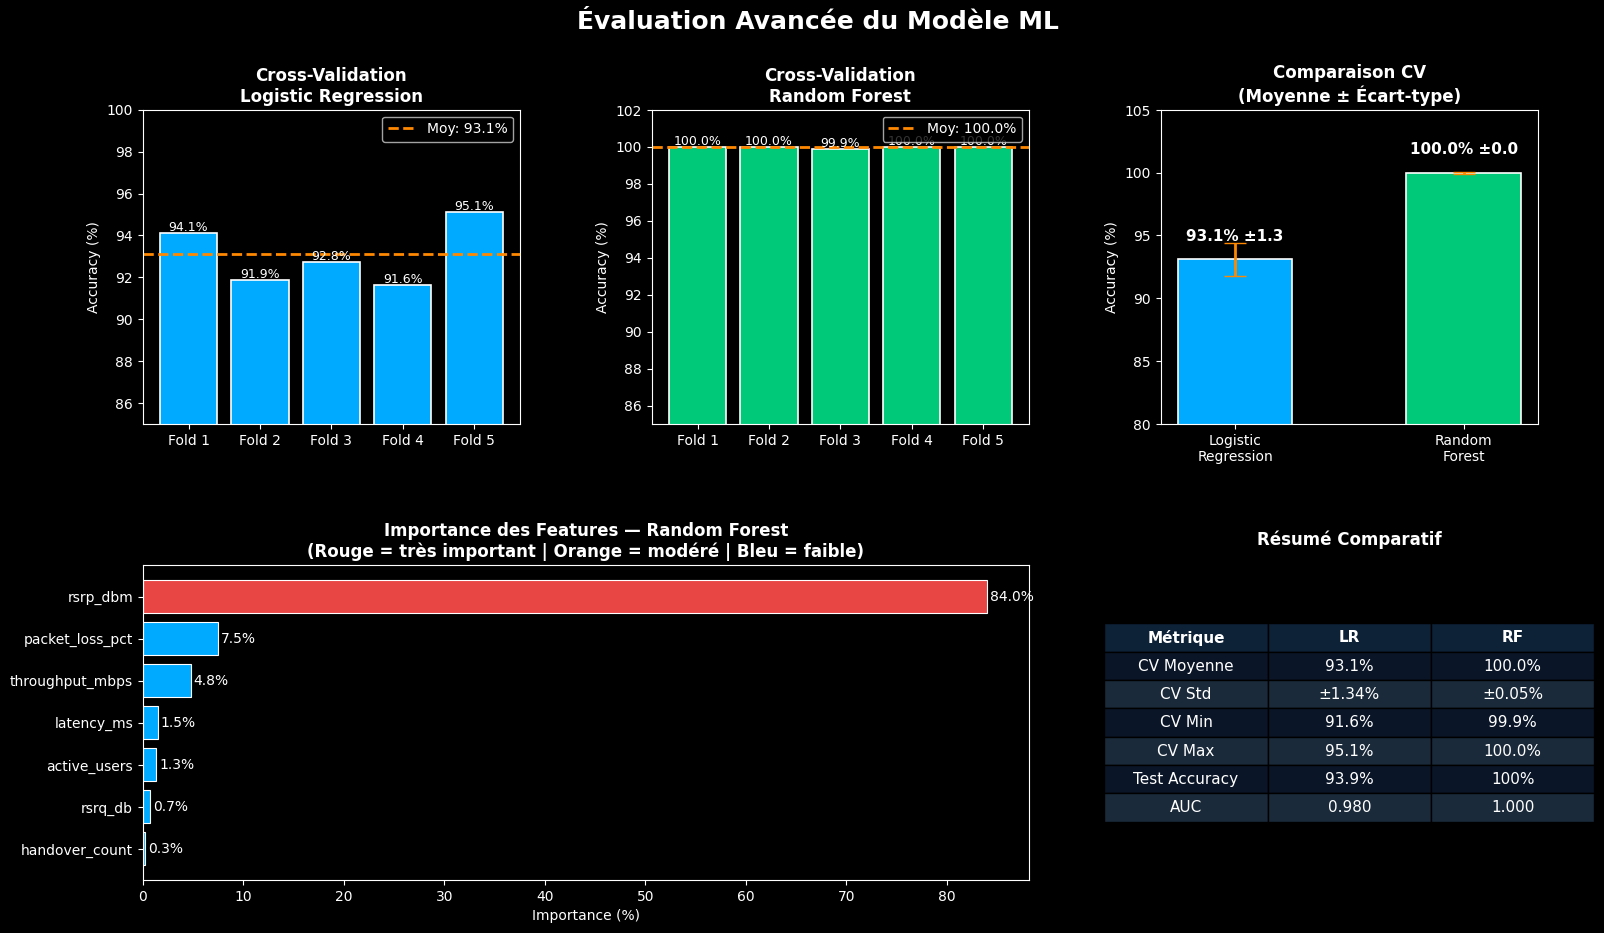


 Graphique sauvegardé : evaluation_avancee.png

 Meilleur modèle : Random Forest
   → Stable sur tous les folds
   → Feature la plus importante : rsrp_dbm (84.0%)


In [24]:
# ================================
# 3. VISUALISATIONS
# ================================
fig = plt.figure(figsize=(18, 10))
fig.suptitle('Évaluation Avancée du Modèle ML', fontsize=18, fontweight='bold', color='white')

gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# --- Graph 1 : CV scores LR ---
ax1 = fig.add_subplot(gs[0, 0])
folds = [f'Fold {i+1}' for i in range(5)]
bars_lr = ax1.bar(folds, cv_lr * 100, color=['#00AAFF']*5, edgecolor='white', linewidth=1.2)
ax1.axhline(y=cv_lr.mean()*100, color='#FF8800', linestyle='--', linewidth=2, label=f'Moy: {cv_lr.mean()*100:.1f}%')
ax1.set_title('Cross-Validation\nLogistic Regression', fontweight='bold', color='white')
ax1.set_ylabel('Accuracy (%)', color='white')
ax1.set_ylim(85, 100)
ax1.legend(fontsize=10)
ax1.tick_params(colors='white')
for bar in bars_lr:
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
             f'{bar.get_height():.1f}%', ha='center', fontsize=9, color='white')

# --- Graph 2 : CV scores RF ---
ax2 = fig.add_subplot(gs[0, 1])
bars_rf = ax2.bar(folds, cv_rf * 100, color=['#00C97A']*5, edgecolor='white', linewidth=1.2)
ax2.axhline(y=cv_rf.mean()*100, color='#FF8800', linestyle='--', linewidth=2, label=f'Moy: {cv_rf.mean()*100:.1f}%')
ax2.set_title('Cross-Validation\nRandom Forest', fontweight='bold', color='white')
ax2.set_ylabel('Accuracy (%)', color='white')
ax2.set_ylim(85, 102)
ax2.legend(fontsize=10)
ax2.tick_params(colors='white')
for bar in bars_rf:
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
             f'{bar.get_height():.1f}%', ha='center', fontsize=9, color='white')

# --- Graph 3 : Comparaison CV ---
ax3 = fig.add_subplot(gs[0, 2])
models = ['Logistic\nRegression', 'Random\nForest']
means  = [cv_lr.mean()*100, cv_rf.mean()*100]
stds   = [cv_lr.std()*100,  cv_rf.std()*100]
colors = ['#00AAFF', '#00C97A']
bars3  = ax3.bar(models, means, color=colors, edgecolor='white', linewidth=1.2, width=0.5)
ax3.errorbar(models, means, yerr=stds, fmt='none', color='#FF8800', capsize=8, linewidth=2)
ax3.set_title('Comparaison CV\n(Moyenne ± Écart-type)', fontweight='bold', color='white')
ax3.set_ylabel('Accuracy (%)', color='white')
ax3.set_ylim(80, 105)
ax3.tick_params(colors='white')
for bar, m, s in zip(bars3, means, stds):
    ax3.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
             f'{m:.1f}% ±{s:.1f}', ha='center', fontsize=11, fontweight='bold', color='white')

# --- Graph 4 : Feature Importance (barh) ---
ax4 = fig.add_subplot(gs[1, :2])
colors_feat = ['#E84545' if v > 0.3 else '#FF8800' if v > 0.1 else '#00AAFF' 
               for v in feat_imp_sorted.values]
bars4 = ax4.barh(feat_imp_sorted.index, feat_imp_sorted.values * 100,
                  color=colors_feat, edgecolor='white', linewidth=0.8)
ax4.set_title('Importance des Features — Random Forest\n(Rouge = très important | Orange = modéré | Bleu = faible)',
              fontweight='bold', color='white')
ax4.set_xlabel('Importance (%)', color='white')
ax4.tick_params(colors='white')
for bar in bars4:
    ax4.text(bar.get_width()+0.3, bar.get_y()+bar.get_height()/2,
             f'{bar.get_width():.1f}%', va='center', fontsize=10, color='white')

# --- Graph 5 : Résumé tableau ---
ax5 = fig.add_subplot(gs[1, 2])
ax5.axis('off')
table_data = [
    ['Métrique', 'LR', 'RF'],
    ['CV Moyenne', f'{cv_lr.mean()*100:.1f}%', f'{cv_rf.mean()*100:.1f}%'],
    ['CV Std', f'±{cv_lr.std()*100:.2f}%', f'±{cv_rf.std()*100:.2f}%'],
    ['CV Min', f'{cv_lr.min()*100:.1f}%', f'{cv_rf.min()*100:.1f}%'],
    ['CV Max', f'{cv_lr.max()*100:.1f}%', f'{cv_rf.max()*100:.1f}%'],
    ['Test Accuracy', '93.9%', '100%'],
    ['AUC', '0.980', '1.000'],
]
tbl = ax5.table(cellText=table_data[1:], colLabels=table_data[0],
                loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1.3, 1.7)
# Couleurs header
for j in range(3):
    tbl[0, j].set_facecolor('#0D2137')
    tbl[0, j].set_text_props(color='white', fontweight='bold')
# Couleurs lignes alternées
for i in range(1, len(table_data)):
    for j in range(3):
        tbl[i, j].set_facecolor('#1A2A3A' if i%2==0 else '#0A1628')
        tbl[i, j].set_text_props(color='white')
ax5.set_title('Résumé Comparatif', fontweight='bold', color='white', pad=15)

plt.savefig('evaluation_avancee.png', dpi=150, bbox_inches='tight', facecolor='#0A1628')
plt.show()

print("\n Graphique sauvegardé : evaluation_avancee.png")
print(f"\n Meilleur modèle : Random Forest")
print(f"   → Stable sur tous les folds")
print(f"   → Feature la plus importante : {feat_imp_sorted.index[-1]} ({feat_imp_sorted.values[-1]*100:.1f}%)")